# Hand-View Grasp Classification for Vision-Guided Prosthetics

**DATA 6610 Final Project (revisited)** - Ryan Pinarija

This notebook redoes `data6610_final_project-v1.ipynb` using the HANDS dataset (Han et al., 2020, Northeastern University).
The task is the same: predict which of 5 grasp types a person would choose, using only the **hand-view** image of an object.

### What changed from v1

| Area | v1 | v2 |
|---|---|---|
| Filenames | `imXXX_YY`: YY assumed to be the object's angle | YY is the **labeler (1–11)**; each copy of an image carries a different person's label |
| Object groups | 107 hand-built ranges; 4 objects split across two groups (leakage) | **103 groups**, one per physical object, verified against the raw data |
| Pixel preprocessing | `/255` for every model | Each backbone's own ImageNet preprocessing |
| Input image | Full 1280×960 frame squashed to 224×224 | Cropped to the object's bounding box (square, 30% padding, aspect ratio kept) |
| Shuffling | None (batches ordered by filename) | Training set reshuffled every epoch |
| LR schedule | ReduceLROnPlateau patience = EarlyStopping patience (never fired) | Patience 3 vs 7 |
| Transfer learning | Base frozen, head only | Stage 1: frozen base → Stage 2: **fine-tune top layers** at a 100× lower LR |
| Blank images | 64 images with no object (failed segmentation) used for training | **Removed** |
| Labels | One labeler's hard label per image | **Soft labels**: the distribution of all 11 labelers' votes for that object orientation |
| Class imbalance | Ignored | Clipped, balanced sample weights |
| Custom CNN | `Flatten → Dense` (18.9M params) | `GlobalAveragePooling` head (~1.2M params) |
| Augmentation | Only the dataset's offline augmentation | + on-the-fly rotation/zoom/shift/contrast |
| Backbones | Custom, MobileNetV2, ResNet50 | + EfficientNetB0 (+ optional VGG16 to match the paper, ConvNeXt-Tiny) |
| Evaluation | One split, accuracy only | **5-fold StratifiedGroupKFold** (mean ± std), confusion matrices, per-class report, top-2, "any-labeler" accuracy, instance-level accuracy, majority baseline, and the **label-noise ceiling** |

> Results are saved per model and fold under `results/`,
> so the notebook can be stopped and restarted without losing finished folds. Set `QUICK_RUN = True` for a fast pass.

In [1]:
import os, json, time, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps

import tensorflow as tf
import keras
from keras import layers, ops
from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import confusion_matrix, classification_report, f1_score

try:
    from IPython.display import display
except ImportError:  # running as a plain script
    display = print

warnings.filterwarnings("ignore", category=UserWarning)
tf.get_logger().setLevel("ERROR")          # hides harmless "retracing" warnings from building models in a loop
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.18.0 | Keras 3.7.0 | GPUs: []


## 1. Configuration

In [2]:
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

LABEL_CSV  = "Dataset_20181026/Labels/Label_Complete.csv"
IMAGE_DIR  = "Dataset_20181026/TrainingImages"
CACHE_DIR  = "cache"
RESULT_DIR = "results"

IMG_SIZE   = 224
BATCH_SIZE = 32
CROP_PAD   = 1.3                      # square crop side = 1.3 x longest bbox side

LABEL_MODE = "soft"                   # "soft" = 11-labeler vote distribution, "hard" = each image's own label
N_FOLDS    = 5
VAL_FRAC   = 0.15                     # fraction of training *groups* held out for early stopping

# (stage-1 epochs, stage-2 fine-tune epochs, # top base layers to unfreeze)
MODEL_CONFIGS = {
    "custom_cnn":     dict(epochs1=60, epochs2=0,  unfreeze=0,  lr1=1e-3),
    "mobilenetv2":    dict(epochs1=30, epochs2=25, unfreeze=40, lr1=1e-3),
    "efficientnetb0": dict(epochs1=30, epochs2=25, unfreeze=40, lr1=1e-3),
    "resnet50":       dict(epochs1=30, epochs2=25, unfreeze=33, lr1=1e-3),   # 33 = conv5 block
    "vgg16":          dict(epochs1=30, epochs2=25, unfreeze=4,  lr1=1e-4),   # last conv block, like the paper
    "convnext_tiny":  dict(epochs1=30, epochs2=25, unfreeze=30, lr1=1e-3),
}
MODELS_TO_RUN = ["custom_cnn", "mobilenetv2", "efficientnetb0", "resnet50"]   # add "vgg16", "convnext_tiny" if you have time/GPU
FINE_TUNE_LR_FACTOR = 0.01            # stage-2 LR = lr1 * 0.01

QUICK_RUN = False                     # True -> 2 folds, fewer epochs, 2 models
SMOKE_TEST = os.environ.get("SMOKE_TEST") == "1"   # used only to test the notebook end-to-end on a tiny subset

if QUICK_RUN or SMOKE_TEST:
    N_FOLDS = 2 if QUICK_RUN else 2
    MODELS_TO_RUN = ["custom_cnn", "mobilenetv2"]
    for c in MODEL_CONFIGS.values():
        e = 1 if SMOKE_TEST else 8
        c["epochs1"] = min(c["epochs1"], e); c["epochs2"] = min(c["epochs2"], e)
    if SMOKE_TEST:
        RESULT_DIR = "results_smoke"

os.makedirs(CACHE_DIR, exist_ok=True); os.makedirs(RESULT_DIR, exist_ok=True)

## 2. Labels and dataset structure

From the dataset README:

* `imXXX_YY.jpg`: **XXX (1–413) is an object-orientation instance** (one object placed in one orientation).
  **YY (1–11) is the labeler.** Each synthetic copy of instance XXX was labeled with labeler YY's top grasp choice.
* 77 instances have only 10 labeled copies. The extra `im*_9.jpg` files for those instances have no label and are ignored.
* Several orientations of the same physical object form a **group**. Groups must never be split across train/test,
  or the test set would contain rotated near-duplicates of training objects. The 103 ranges below were verified against the raw data: each instance's eye-view image matches the file checksum of
  exactly one `RawData/<object>_<orientation>/` photo, which identifies its physical object. This corrected 4 objects that v1 had split across
  two groups (`crown`, `hairdryer`, `knife`, `noteBook`).

Labels in `Label_Complete.csv` run **0–4**, in the paper's Fig. 4 order: 0 Open Palm, 1 Medium Wrap, 2 Power Sphere, 3 Parallel Extension, 4 Palmar Pinch.
This was confirmed visually: high-agreement examples of 1 are bottles and cups, 2 are apples and balls, 3 are flat boxes, 4 are thin objects
such as candy canes and swabs. Class 0, the hand's resting pose, was chosen only 8 times.

In [3]:
CLASS_NAMES = ["Open Palm", "Medium Wrap", "Power Sphere", "Parallel Extension", "Palmar Pinch"]
NUM_CLASSES = len(CLASS_NAMES)

df = pd.read_csv(LABEL_CSV)
df["instance"] = df["image_name"].str.extract(r"im(\d+)_").astype(int)
df["labeler"]  = df["image_name"].str.extract(r"_(\d+)\.").astype(int)

ranges = ['1-3', '4-6', '7-9', '10-13', '14-16', '17-19', '20-22', '23-26', '27-32', '33-36', '37-38', '39-40', '41-43', '44-48', '49-52', '53-57', '58-62',
          '63-66', '67-69', '70-73', '74-78', '79-80', '81', '82-84', '85-90', '91-93', '94-100', '101-107', '108-112', '113-118', '119-124',
          '125-128', '129-132', '133-136', '137-141', '142-144', '145-149', '150-152', '153-155', '156-161', '162-164', '165-168', '169-171',
          '172-174', '175-178', '179-181', '182-185', '186-187', '188-190', '191-195', '196-197', '198-200', '201-204', '205-207', '208-213',
          '214-219', '220-223', '224-226', '227-232', '233-235', '236-239', '240-242', '243-245', '246-251', '252-254', '255-258', '259-262', '263-264',
          '265-268', '269-273', '274-279', '280-285', '286-291', '292-294', '295-299', '300-303', '304-306', '307-310', '311-314', '315-320', '321-326',
          '327-329', '330-332', '333-337', '338-342', '343-346', '347-349', '350-352', '353-355', '356-359', '360-364', '365-368', '369-370', '371-374',
          '375-379', '380-383', '384-388', '389-392', '393-396', '397-401', '402-403', '404-406', '407-413']
instance_to_group = {}
for gid, r in enumerate(ranges):
    a, b = (map(int, r.split("-")) if "-" in r else (int(r), int(r)))
    for i in range(a, b + 1):
        instance_to_group[i] = gid
df["group"] = df["instance"].map(instance_to_group)
assert df["group"].notna().all() and len(instance_to_group) == 413

# 64 images (every copy of 6 instances) have an empty bounding box. Inspection shows they are pure background noise:
# the dataset's object segmentation failed, so they contain no object but still carry grasp labels. Drop them.
empty_box = ((df["xmax"] - df["xmin"]) < 10) | ((df["ymax"] - df["ymin"]) < 10)
print(f"Dropping {empty_box.sum()} blank images from instances {sorted(df.loc[empty_box, 'instance'].unique())}")
BLANK_EXAMPLES = df.loc[empty_box, "image_name"].head(4).tolist()
df = df.loc[~empty_box].reset_index(drop=True)

# Soft label = distribution of all labelers' votes for the instance
counts = pd.crosstab(df["instance"], df["label"]).reindex(columns=range(NUM_CLASSES), fill_value=0)
soft_by_instance = counts.div(counts.sum(axis=1), axis=0)
df["majority"] = df["instance"].map(soft_by_instance.idxmax(axis=1))   # majority-vote grasp per instance

SOFT     = soft_by_instance.loc[df["instance"]].values.astype("float32")   # (N, 5)
HARD     = df["label"].values                                               # each image's own labeler label
MAJORITY = df["majority"].values
GROUPS   = df["group"].values
INSTANCE = df["instance"].values

print(f"{len(df)} images | {df['instance'].nunique()} instances | {df['group'].nunique()} object groups")
df.head()

Dropping 64 blank images from instances [220, 223, 359, 386, 405, 406]
4402 images | 407 instances | 103 object groups


,image_name,xmin,xmax,ymin,ymax,label,instance,labeler,group,majority
0,im100_1.jpg,734,1240,2,80,4,100,1,26,4
1,im101_1.jpg,391,877,99,289,3,101,1,27,1
2,im102_1.jpg,745,997,72,274,1,102,1,27,1
3,im103_1.jpg,352,864,754,934,2,103,1,27,1
4,im104_1.jpg,529,1109,672,888,2,104,1,27,2


In [4]:
len(HARD)

4402

### 2.1 Class balance and labeler agreement

Two properties of the labels set hard limits on the task:

1. **Class imbalance.** "Open Palm" appears 8 times out of ~4,400, so this is effectively a 4-class problem.
   A model that always predicts the most common class already scores ~31%.
2. **Labelers disagree.** Every copy of an instance shows the same object, but the copies carry different people's labels.
   No model can match them all. The best possible accuracy against each image's own label comes from always predicting the
   majority vote. That is the **label-noise ceiling** below.

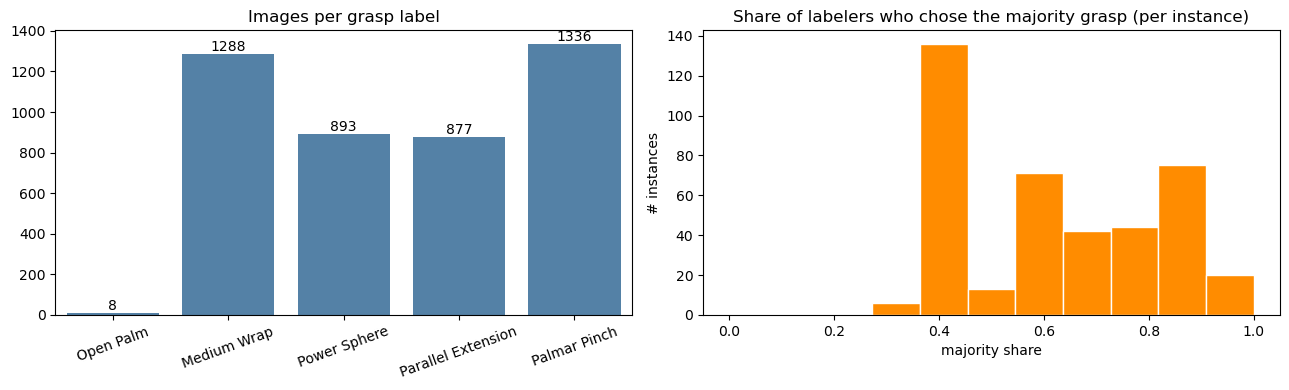

Majority-class baseline : 30.3%
Label-noise ceiling     : 61.0%  (accuracy of an upper-bound classifier that knows every instance's majority vote)


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
vc = df["label"].value_counts().reindex(range(NUM_CLASSES), fill_value=0)
sns.barplot(x=CLASS_NAMES, y=vc.values, ax=axes[0], color="steelblue")
axes[0].set_title("Images per grasp label"); axes[0].tick_params(axis="x", rotation=20)
for i, v in enumerate(vc.values):
    axes[0].text(i, v, str(v), ha="center", va="bottom")

agreement = soft_by_instance.max(axis=1)
axes[1].hist(agreement, bins=np.linspace(0, 1, 12), color="darkorange", edgecolor="white")
axes[1].set_title("Share of labelers who chose the majority grasp (per instance)")
axes[1].set_xlabel("majority share"); axes[1].set_ylabel("# instances")
plt.tight_layout(); plt.show()

ceiling = SOFT[np.arange(len(df)), MAJORITY].mean()
print(f"Majority-class baseline : {vc.max() / vc.sum():.1%}")
print(f"Label-noise ceiling     : {ceiling:.1%}  (accuracy of an upper-bound classifier that knows every instance's majority vote)")

## 3. Preprocessing: crop to the object

The training images are 1280×960 and the object usually fills a small part of the frame, so resizing the whole frame
to 224×224 leaves the object only a few dozen pixels wide. Here each image is cropped to a **square** around its bounding box
(30% padding, shifted to stay inside the frame), then resized to 224×224.

The 64 images dropped in Section 2 are shown below. They are pure noise (the dataset's segmentation failed), yet v1 trained on them with grasp labels attached.
The crop function still falls back to letterboxing the full frame if it ever meets an empty box.

The crops are cached as `uint8` in `cache/` (~670 MB), so this step only runs once.

In [6]:
def crop_square(img, xmin, xmax, ymin, ymax, pad=CROP_PAD, size=IMG_SIZE):
    W, H = img.size
    w, h = xmax - xmin, ymax - ymin
    if w < 10 or h < 10:                               # empty/degenerate bounding box
        return ImageOps.pad(img, (size, size), color=tuple(np.median(np.asarray(img), axis=(0, 1)).astype(int)))
    side = int(min(max(w, h) * pad, min(W, H)))
    cx, cy = (xmin + xmax) / 2, (ymin + ymax) / 2
    left = int(np.clip(cx - side / 2, 0, W - side))
    top  = int(np.clip(cy - side / 2, 0, H - side))
    return img.crop((left, top, left + side, top + side)).resize((size, size), Image.BILINEAR)

cache_file = os.path.join(CACHE_DIR, f"crops_{IMG_SIZE}_n{len(df)}.npy")
if os.path.exists(cache_file):
    X = np.load(cache_file)
else:
    X = np.zeros((len(df), IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
    t0 = time.time()
    for i, row in enumerate(df.itertuples()):
        img = Image.open(os.path.join(IMAGE_DIR, row.image_name)).convert("RGB")
        X[i] = np.asarray(crop_square(img, row.xmin, row.xmax, row.ymin, row.ymax))
        if i % 500 == 0:
            print(f"  {i}/{len(df)}  ({time.time() - t0:.0f}s)")
    np.save(cache_file, X)
print("X:", X.shape, X.dtype)

X: (4402, 224, 224, 3) uint8


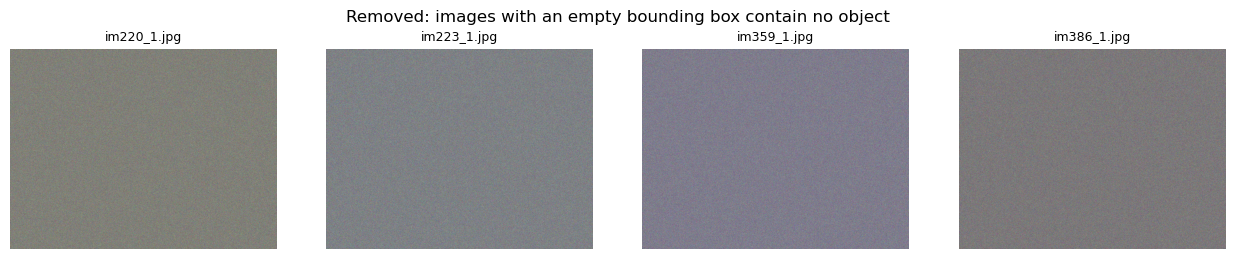

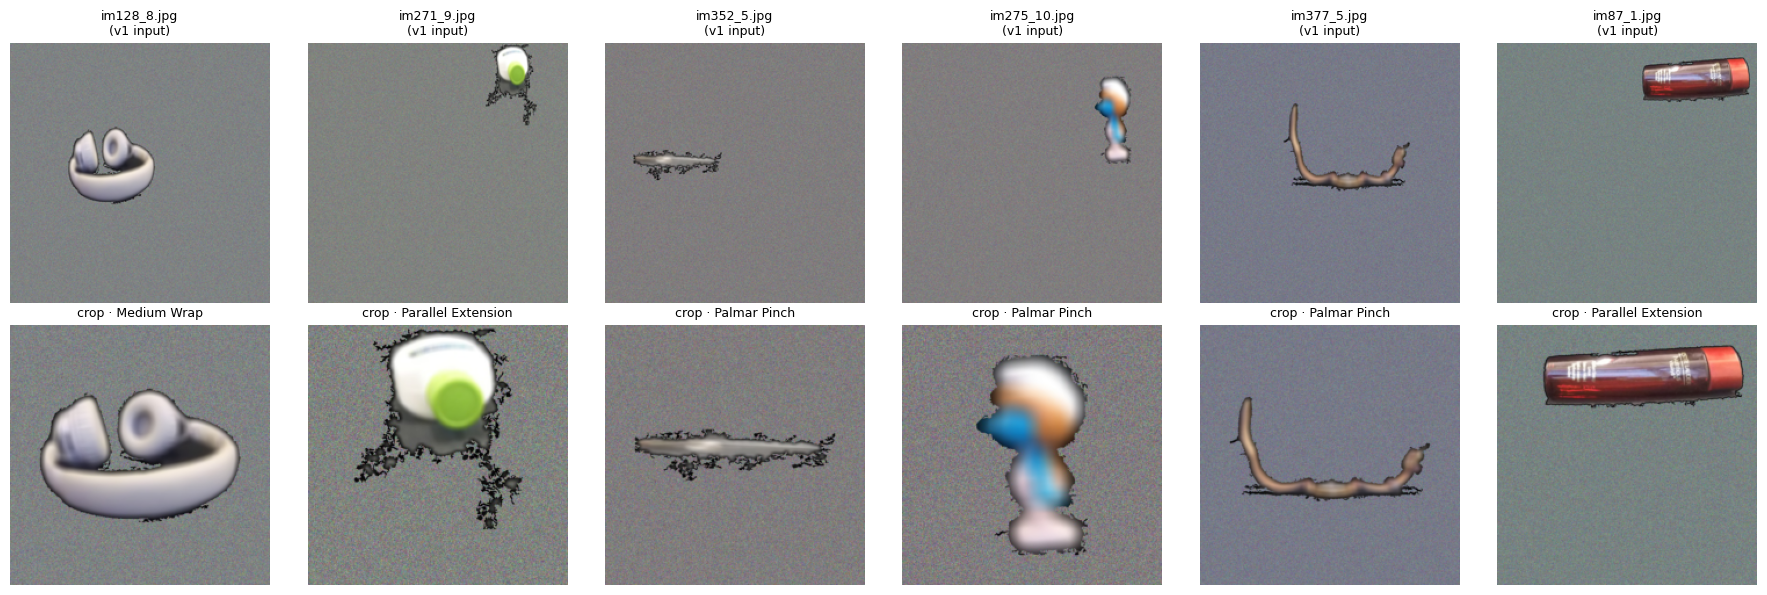

In [7]:
# The dropped "blank" images
fig, axes = plt.subplots(1, len(BLANK_EXAMPLES), figsize=(3.2 * len(BLANK_EXAMPLES), 2.6))
for a, n in zip(np.atleast_1d(axes), BLANK_EXAMPLES):
    a.imshow(Image.open(os.path.join(IMAGE_DIR, n))); a.set_title(n, fontsize=9); a.axis("off")
plt.suptitle("Removed: images with an empty bounding box contain no object"); plt.tight_layout(); plt.show()

# Before/after: full frame vs. object crop
rng = np.random.default_rng(SEED)
sample = rng.choice(len(df), 6, replace=False)
fig, axes = plt.subplots(2, 6, figsize=(18, 6))
for j, i in enumerate(sample):
    full = Image.open(os.path.join(IMAGE_DIR, df.image_name[i])).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    axes[0, j].imshow(full); axes[0, j].set_title(f"{df.image_name[i]}\n(v1 input)", fontsize=9)
    axes[1, j].imshow(X[i]);  axes[1, j].set_title(f"crop · {CLASS_NAMES[HARD[i]]}", fontsize=9)
for a in axes.ravel():
    a.axis("off")
plt.tight_layout(); plt.show()

## 4. Models

Every model takes raw 0–255 pixels. Augmentation and the backbone's own preprocessing run inside the model,
so the correct preprocessing can't be forgotten. Augmentation layers only run during training.

* **Augmentation:** small rotation (±~11°), zoom, shift, contrast. No flips, since the object's orientation relative to the hand
  is exactly what decides the grasp.
* **Preprocessing:** MobileNetV2 → [-1, 1]; ResNet50/VGG16 → BGR minus ImageNet mean ("caffe"); EfficientNet/ConvNeXt include
  their own preprocessing; the custom CNN → [0, 1].
* **Transfer models:** the backbone is called with `training=False`, which keeps BatchNorm in inference mode during fine-tuning.

In [8]:
IMAGENET_BGR_MEAN = np.array([103.939, 116.779, 123.68], dtype="float32")

def caffe_preprocess(x):
    return ops.flip(x, axis=-1) - IMAGENET_BGR_MEAN

def augmentation():
    return keras.Sequential([
        layers.RandomRotation(0.03, fill_mode="reflect"),
        layers.RandomZoom(0.1, fill_mode="reflect"),
        layers.RandomTranslation(0.05, 0.05, fill_mode="reflect"),
        layers.RandomContrast(0.15),
    ], name="augment")

def get_backbone(name, inp):
    shape = (IMG_SIZE, IMG_SIZE, 3)
    A = keras.applications
    if name == "mobilenetv2":
        return A.MobileNetV2(include_top=False, weights="imagenet", input_shape=shape), layers.Rescaling(1 / 127.5, offset=-1)
    if name == "resnet50":
        return A.ResNet50(include_top=False, weights="imagenet", input_shape=shape), layers.Lambda(caffe_preprocess)
    if name == "vgg16":
        return A.VGG16(include_top=False, weights="imagenet", input_shape=shape), layers.Lambda(caffe_preprocess)
    if name == "efficientnetb0":
        return A.EfficientNetB0(include_top=False, weights="imagenet", input_shape=shape), None
    if name == "convnext_tiny":
        return A.ConvNeXtTiny(include_top=False, weights="imagenet", input_shape=shape), None
    raise ValueError(name)

def build_model(name):
    inp = keras.Input((IMG_SIZE, IMG_SIZE, 3), name="image_0_255")
    x = augmentation()(inp)
    base = None
    if name == "custom_cnn":
        x = layers.Rescaling(1 / 255)(x)
        for filters in (32, 64, 128, 256):
            x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
            x = layers.BatchNormalization()(x); x = layers.Activation("relu")(x)
            x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
            x = layers.BatchNormalization()(x); x = layers.Activation("relu")(x)
            x = layers.MaxPooling2D()(x)
            x = layers.Dropout(0.2)(x)
        x = layers.GlobalAveragePooling2D()(x)          
    else:
        base, prep = get_backbone(name, inp)
        base.trainable = False
        if prep is not None:
            x = prep(x)
        x = base(x, training=False)
        x = layers.GlobalAveragePooling2D()(x)
        x = layers.Dropout(0.3)(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inp, out, name=name), base

def compile_model(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss="categorical_crossentropy",
                  metrics=[keras.metrics.CategoricalAccuracy(name="acc"),
                           keras.metrics.TopKCategoricalAccuracy(k=2, name="top2")])

def unfreeze_top(base, n):
    base.trainable = True
    for layer in base.layers[:-n]:
        layer.trainable = False
    for layer in base.layers:                           # keep BatchNorm statistics frozen
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

for name in MODELS_TO_RUN:
    m, _ = build_model(name)
    n_tr = sum(np.prod(w.shape) for w in m.trainable_weights)
    print(f"{name:15s} total params {m.count_params():>11,}  | trainable in stage 1 {n_tr:>10,}")
    del m
keras.backend.clear_session()

custom_cnn      total params   1,242,213  | trainable in stage 1  1,240,293
mobilenetv2     total params   2,587,205  | trainable in stage 1    329,221
efficientnetb0  total params   4,378,792  | trainable in stage 1    329,221
resnet50        total params  24,113,541  | trainable in stage 1    525,829


## 5. Data pipeline, class weights, and training loop

* **Targets:** `LABEL_MODE="soft"` trains on the 11-labeler vote distribution. `"hard"` reproduces v1's single-label setup.
* **Class weights:** "balanced" weights from the training fold, **clipped at 5×**. Unclipped, the 8-image Open Palm class would get a weight of about 100.
  For soft targets, an image's weight is the vote-weighted average of the class weights.
* **Callbacks:** EarlyStopping (patience 7, restores the best weights) and ReduceLROnPlateau (patience 3), both on validation loss.

In [9]:
AUTOTUNE = tf.data.AUTOTUNE
ONE_HOT = np.eye(NUM_CLASSES, dtype="float32")[HARD]
TARGETS = SOFT if LABEL_MODE == "soft" else ONE_HOT

def class_weight_vector(idx, clip=5.0):
    present = np.unique(HARD[idx])
    cw = compute_class_weight("balanced", classes=present, y=HARD[idx])
    vec = np.ones(NUM_CLASSES, dtype="float32")
    vec[present] = np.minimum(cw, clip)
    return vec

def make_ds(idx, training, sample_weights=None):
    tensors = (X[idx], TARGETS[idx]) if sample_weights is None else (X[idx], TARGETS[idx], sample_weights)
    ds = tf.data.Dataset.from_tensor_slices(tensors)
    if training:
        ds = ds.shuffle(len(idx), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.map(lambda x, *rest: (tf.cast(x, tf.float32), *rest), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

def callbacks(patience_es=7, patience_lr=3):
    return [keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience_es, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=patience_lr, min_lr=1e-7)]

def train_one(name, train_idx, val_idx):
    cfg = MODEL_CONFIGS[name]
    cw = class_weight_vector(train_idx)
    sw = (TARGETS[train_idx] @ cw).astype("float32")
    ds_tr, ds_va = make_ds(train_idx, True, sw), make_ds(val_idx, False)

    keras.backend.clear_session(); tf.random.set_seed(SEED)
    model, base = build_model(name)
    compile_model(model, cfg["lr1"])
    h1 = model.fit(ds_tr, validation_data=ds_va, epochs=cfg["epochs1"], callbacks=callbacks(), verbose=2)
    history = {k: list(map(float, v)) for k, v in h1.history.items()}
    stage2_start = len(history["loss"])

    if base is not None and cfg["epochs2"] > 0:
        unfreeze_top(base, cfg["unfreeze"])
        compile_model(model, cfg["lr1"] * FINE_TUNE_LR_FACTOR)
        h2 = model.fit(ds_tr, validation_data=ds_va, epochs=cfg["epochs2"], callbacks=callbacks(), verbose=2)
        for k, v in h2.history.items():
            history.setdefault(k, []).extend(map(float, v))
    return model, history, stage2_start

## 6. Evaluation metrics

With 11 labelers who often disagree, "accuracy" can mean several things. All of these are reported:

| Metric | What it answers | Correct when the prediction… |
|---|---|---|
| `acc_own` | Same metric as v1, for comparison | matches that image's own labeler |
| `acc_majority` | Did it pick what most people would? |  matches the majority vote for the instance |
| `acc_any` | Did it pick a grasp anyone chose? (fair for a prosthetic) |  matches **any** labeler's choice for the instance |
| `top2_own` | Was the right grasp in its top 2? |  puts the image's own label in its top 2 |
| `acc_instance` | Averaging over an instance's ~11 copies, is it right? |  after averaging the ~11 copies of an instance, the prediction matches the majority vote |
| `macro_f1` | Does it work on every class, not just the big ones? |  macro F1 against the image's own labels, averaged over the 4 learnable grasps (Open Palm excluded: 8 labels, never a majority vote) |
| `binary_acc` | The paper's metric. The untrained model already scores 0.80 on it. |  ≥ 0.5 on the true class and < 0.5 on the others, scored over all 5 outputs (**how Keras scores sigmoid + binary cross-entropy, as in the paper**) |

Each fold also records the **majority-class baseline** and the **label-noise ceiling** on its own test set.

In [10]:
# Macro-F1 is averaged over the 4 learnable grasps. Open Palm (0) has 8 labels in the whole dataset, each a single labeler
# disagreeing with the other 10, and is never an instance's majority vote, so its F1 is always 0 and would cut the average by ~20%.
F1_CLASSES = list(range(1, NUM_CLASSES))

def macro_f1(y_true, y_pred):
    return float(f1_score(y_true, y_pred, average="macro", labels=F1_CLASSES, zero_division=0))

def compute_metrics(probs, idx, train_idx):
    pred = probs.argmax(1)
    own, maj = HARD[idx], MAJORITY[idx]
    top2 = np.argsort(-probs, axis=1)[:, :2]

    inst = pd.DataFrame(probs, index=INSTANCE[idx]).groupby(level=0).mean()
    inst_pred = inst.values.argmax(1)
    inst_true = soft_by_instance.loc[inst.index].values.argmax(1)

    train_majority_class = np.bincount(HARD[train_idx], minlength=NUM_CLASSES).argmax()
    return {
        "acc_own":      float((pred == own).mean()),
        "acc_majority": float((pred == maj).mean()),            
        "acc_any":      float((SOFT[idx, pred] > 0).mean()),    
        "top2_own":     float((top2 == own[:, None]).any(1).mean()),
        "acc_instance": float((inst_pred == inst_true).mean()),
        "macro_f1":     macro_f1(own, pred),
        "binary_acc":   float(((probs >= 0.5) == ONE_HOT[idx].astype(bool)).mean()),
        "baseline_majority_class": float((own == train_majority_class).mean()),
        "ceiling_own":  float(SOFT[idx, maj].mean()),
    }

## 7. Cross-validation

The **outer loop** is a 5-fold `StratifiedGroupKFold` over object groups, stratified by the majority label. Each object appears in exactly one test fold.
Inside each fold, 15% of the training groups are held out as a validation set for early stopping.
Every model sees the same folds. Finished folds are saved to `results/` and skipped on re-run.

In [11]:
sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
FOLDS = []
for k, (trval_idx, test_idx) in enumerate(sgkf.split(np.zeros(len(df)), MAJORITY, GROUPS)):
    gss = GroupShuffleSplit(n_splits=1, test_size=VAL_FRAC, random_state=SEED + k)
    tr_rel, va_rel = next(gss.split(trval_idx, groups=GROUPS[trval_idx]))
    tr, va = trval_idx[tr_rel], trval_idx[va_rel]
    assert not (set(GROUPS[tr]) & set(GROUPS[test_idx])) and not (set(GROUPS[va]) & set(GROUPS[test_idx]))
    FOLDS.append((tr, va, test_idx))
    print(f"fold {k}: train {len(tr):4d} imgs / {len(set(GROUPS[tr])):3d} groups | "
          f"val {len(va):4d} / {len(set(GROUPS[va])):2d} | test {len(test_idx):4d} / {len(set(GROUPS[test_idx])):2d}")

if SMOKE_TEST:  # tiny subsets so the whole notebook runs in a few minutes
    rs = np.random.default_rng(0)
    FOLDS = [tuple(rs.choice(a, min(len(a), n), replace=False) for a, n in zip(f, (96, 32, 64))) for f in FOLDS]

fold 0: train 3012 imgs /  69 groups | val  520 / 13 | test  870 / 21
fold 1: train 2964 imgs /  68 groups | val  556 / 13 | test  882 / 22
fold 2: train 2934 imgs /  70 groups | val  509 / 13 | test  959 / 20
fold 3: train 3050 imgs /  70 groups | val  453 / 13 | test  899 / 20
fold 4: train 3012 imgs /  70 groups | val  598 / 13 | test  792 / 20


In [12]:
def result_paths(name, k):
    base = os.path.join(RESULT_DIR, f"{name}_fold{k}")
    return base + ".json", base + "_probs.npy"

for name in MODELS_TO_RUN:
    for k, (tr, va, te) in enumerate(FOLDS):
        jpath, ppath = result_paths(name, k)
        if os.path.exists(jpath):
            print(f"[skip] {name} fold {k} (already done)")
            continue
        print(f"\n===== {name} | fold {k + 1}/{len(FOLDS)} =====")
        t0 = time.time()
        model, history, stage2_start = train_one(name, tr, va)
        probs = model.predict(make_ds(te, False), verbose=0)
        metrics = compute_metrics(probs, te, tr)
        metrics["minutes"] = (time.time() - t0) / 60
        np.save(ppath, probs)
        with open(jpath, "w") as f:
            json.dump({"metrics": metrics, "history": history, "stage2_start": stage2_start,
                       "test_idx": te.tolist()}, f)
        print({k_: round(v, 3) for k_, v in metrics.items()})
        del model

[skip] custom_cnn fold 0 (already done)
[skip] custom_cnn fold 1 (already done)
[skip] custom_cnn fold 2 (already done)
[skip] custom_cnn fold 3 (already done)
[skip] custom_cnn fold 4 (already done)
[skip] mobilenetv2 fold 0 (already done)
[skip] mobilenetv2 fold 1 (already done)
[skip] mobilenetv2 fold 2 (already done)
[skip] mobilenetv2 fold 3 (already done)
[skip] mobilenetv2 fold 4 (already done)
[skip] efficientnetb0 fold 0 (already done)
[skip] efficientnetb0 fold 1 (already done)
[skip] efficientnetb0 fold 2 (already done)
[skip] efficientnetb0 fold 3 (already done)
[skip] efficientnetb0 fold 4 (already done)
[skip] resnet50 fold 0 (already done)
[skip] resnet50 fold 1 (already done)
[skip] resnet50 fold 2 (already done)
[skip] resnet50 fold 3 (already done)
[skip] resnet50 fold 4 (already done)


## 8. Results
### 8.1 Cross-validated summary (mean ± std across folds)

In [13]:
def load_results(name):
    out = []
    for k in range(len(FOLDS)):
        jpath, ppath = result_paths(name, k)
        if os.path.exists(jpath):
            with open(jpath) as f:
                r = json.load(f)
            r["probs"], r["fold"] = np.load(ppath), k
            r["metrics"]["macro_f1"] = macro_f1(HARD[r["test_idx"]], r["probs"].argmax(1))   # recomputed with the current definition
            out.append(r)
    return out

RESULTS = {n: load_results(n) for n in MODELS_TO_RUN}
RESULTS = {n: r for n, r in RESULTS.items() if r}

rows = []
for name, rs in RESULTS.items():
    for r in rs:
        rows.append({"model": name, "fold": r["fold"], **r["metrics"]})
per_fold = pd.DataFrame(rows)

metric_cols = ["acc_own", "acc_majority", "acc_any", "top2_own", "acc_instance", "macro_f1", "binary_acc"]
summary = per_fold.groupby("model")[metric_cols + ["baseline_majority_class", "ceiling_own", "minutes"]].agg(["mean", "std"])
pretty = pd.DataFrame({c: summary[c]["mean"].map("{:.3f}".format) + " ± " + summary[c]["std"].fillna(0).map("{:.3f}".format)
                       for c in metric_cols + ["baseline_majority_class", "ceiling_own"]})
pretty["folds"] = per_fold.groupby("model").size()
pretty = pretty.sort_values("acc_own", ascending=False)
display(pretty)
pretty.to_csv(os.path.join(RESULT_DIR, "summary.csv"))

,acc_own,acc_majority,acc_any,top2_own,acc_instance,macro_f1,binary_acc,baseline_majority_class,ceiling_own,folds
model,,,,,,,,,,
efficientnetb0,0.491 ± 0.045,0.605 ± 0.059,0.972 ± 0.014,0.732 ± 0.045,0.628 ± 0.055,0.463 ± 0.044,0.823 ± 0.012,0.279 ± 0.029,0.611 ± 0.038,5
resnet50,0.490 ± 0.040,0.579 ± 0.033,0.959 ± 0.028,0.732 ± 0.028,0.587 ± 0.045,0.462 ± 0.040,0.820 ± 0.009,0.279 ± 0.029,0.611 ± 0.038,5
mobilenetv2,0.480 ± 0.037,0.576 ± 0.018,0.944 ± 0.021,0.708 ± 0.028,0.585 ± 0.025,0.451 ± 0.039,0.820 ± 0.009,0.279 ± 0.029,0.611 ± 0.038,5
custom_cnn,0.406 ± 0.068,0.454 ± 0.098,0.911 ± 0.034,0.663 ± 0.034,0.464 ± 0.094,0.343 ± 0.083,0.800 ± 0.016,0.279 ± 0.029,0.611 ± 0.038,5


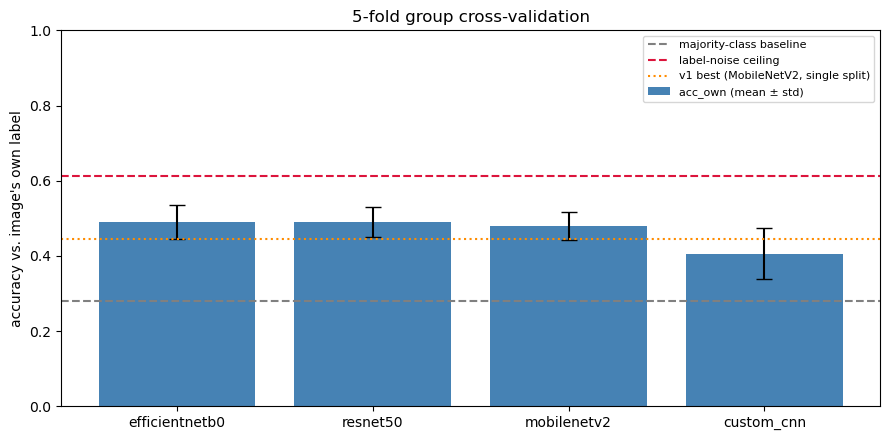

In [14]:
# Comparison chart: v1-style accuracy vs. baseline and ceiling
order = pretty.index.tolist()
means = summary.loc[order, ("acc_own", "mean")]
stds  = summary.loc[order, ("acc_own", "std")].fillna(0)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(order, means, yerr=stds, capsize=6, color="steelblue", label="acc_own (mean ± std)")
ax.axhline(per_fold["baseline_majority_class"].mean(), color="gray", ls="--", label="majority-class baseline")
ax.axhline(per_fold["ceiling_own"].mean(), color="crimson", ls="--", label="label-noise ceiling")
ax.axhline(0.446, color="darkorange", ls=":", label="v1 best (MobileNetV2, single split)")
ax.set_ylim(0, 1); ax.set_ylabel("accuracy vs. image's own label")
ax.set_title(f"{len(FOLDS)}-fold group cross-validation")
ax.legend(loc="upper right", fontsize=8); plt.tight_layout(); plt.show()

### 8.2 Training curves (fold 1 of each model)
The dotted vertical line marks the start of stage-2 fine-tuning.

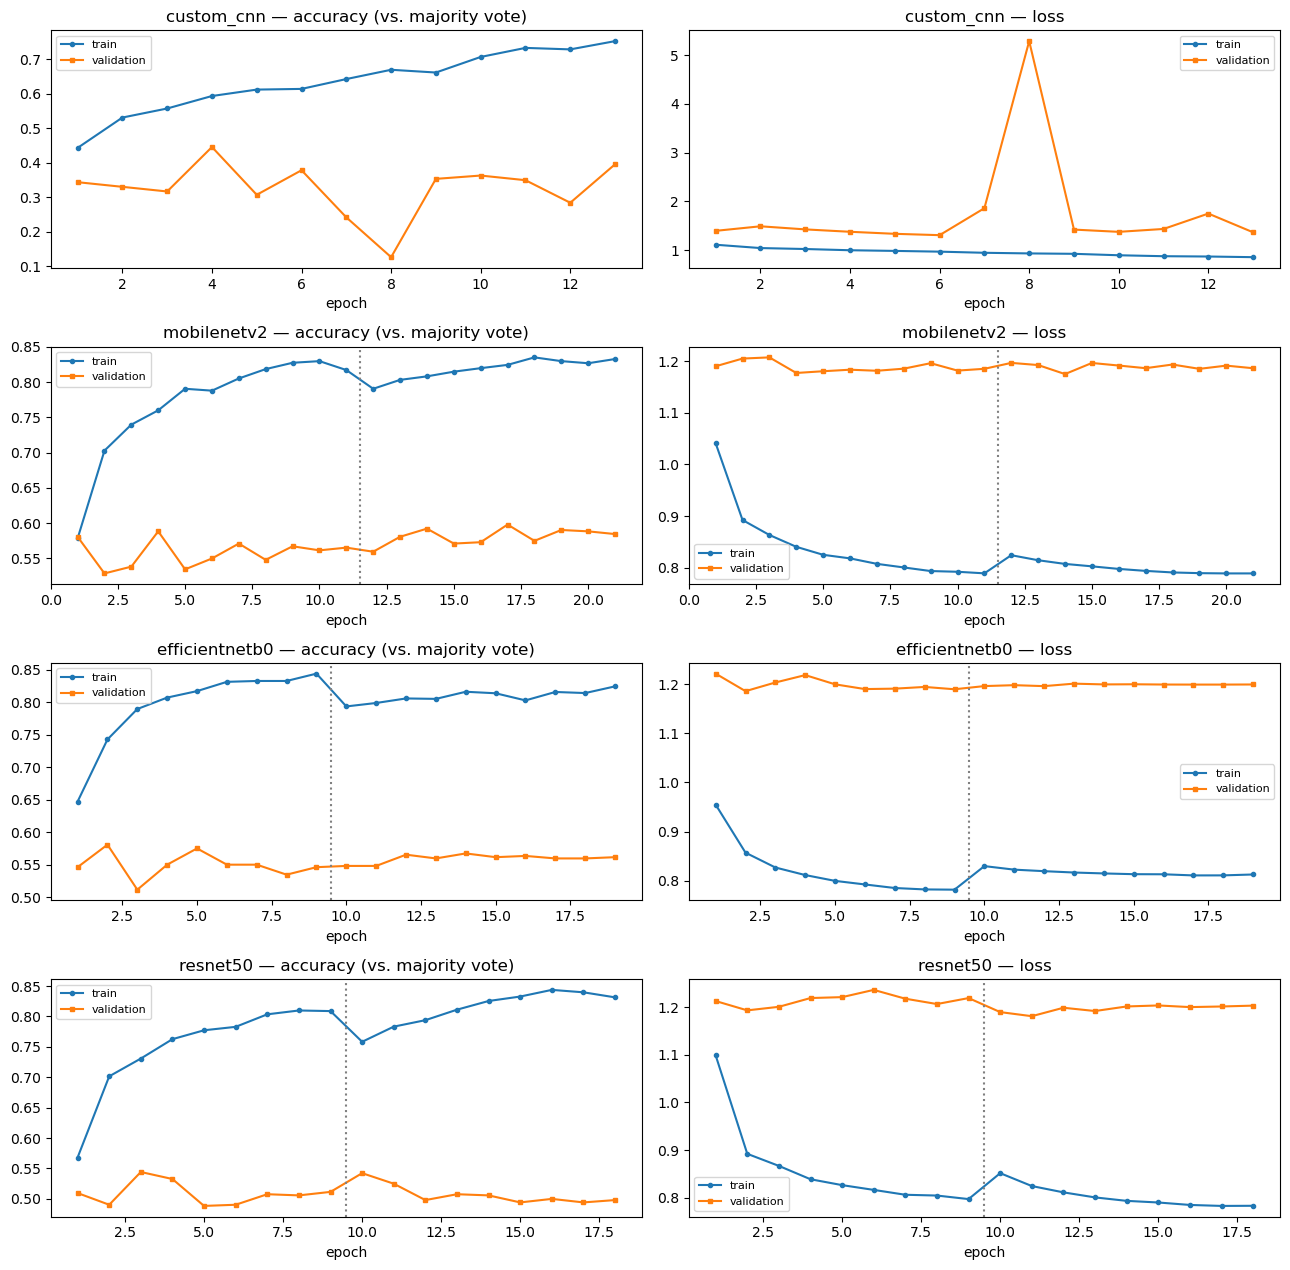

In [15]:
fig, axes = plt.subplots(len(RESULTS), 2, figsize=(13, 3.2 * len(RESULTS)), squeeze=False)
for row, (name, rs) in enumerate(RESULTS.items()):
    h, s2 = rs[0]["history"], rs[0]["stage2_start"]
    ep = np.arange(1, len(h["loss"]) + 1)
    for col, (tr_key, va_key, title) in enumerate([("acc", "val_acc", "accuracy (vs. majority vote)"), ("loss", "val_loss", "loss")]):
        ax = axes[row, col]
        ax.plot(ep, h[tr_key], "o-", ms=3, label="train"); ax.plot(ep, h[va_key], "s-", ms=3, label="validation")
        if s2 < len(ep):
            ax.axvline(s2 + 0.5, color="gray", ls=":")
        ax.set_title(f"{name} — {title}"); ax.set_xlabel("epoch"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 8.3 Confusion matrices (all test folds pooled, row-normalized)
Rows are each image's own label. A column that lights up for every row means the model has collapsed to predicting one class.

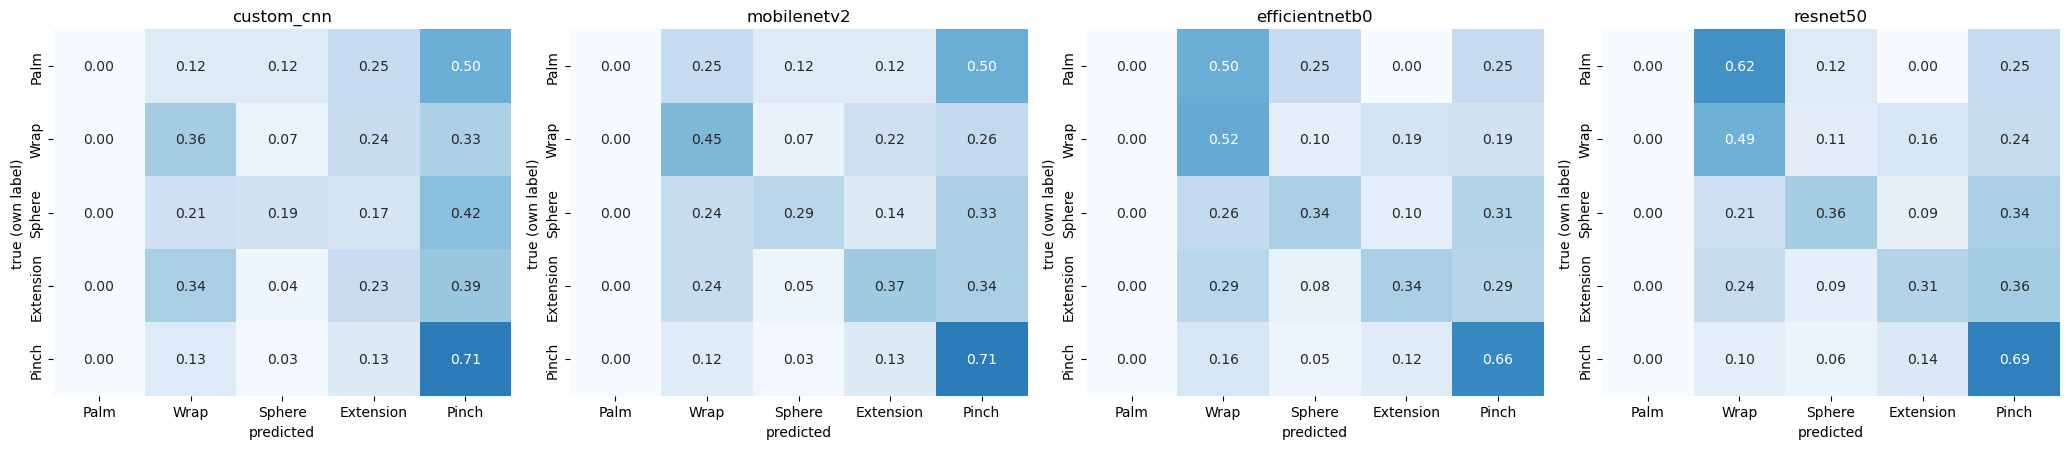

In [16]:
fig, axes = plt.subplots(1, len(RESULTS), figsize=(5.2 * len(RESULTS), 4.6), squeeze=False)
for ax, (name, rs) in zip(axes[0], RESULTS.items()):
    y_true = np.concatenate([HARD[r["test_idx"]] for r in rs])
    y_pred = np.concatenate([r["probs"].argmax(1) for r in rs])
    cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES), normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax,
                xticklabels=[c.split()[-1] for c in CLASS_NAMES], yticklabels=[c.split()[-1] for c in CLASS_NAMES])
    ax.set_title(name); ax.set_xlabel("predicted"); ax.set_ylabel("true (own label)")
plt.tight_layout(); plt.show()

### 8.4 Per-class report for the best model
Macro averages cover the 4 learnable grasps, matching `macro_f1` above.

In [17]:
best = pretty.index[0]
rs = RESULTS[best]
y_true = np.concatenate([HARD[r["test_idx"]] for r in rs])
y_pred = np.concatenate([r["probs"].argmax(1) for r in rs])
print(f"Best model by acc_own: {best}\n")
print(classification_report(y_true, y_pred, labels=F1_CLASSES, target_names=[CLASS_NAMES[c] for c in F1_CLASSES], zero_division=0))
print(f"Open Palm (excluded above): {(y_true == 0).sum()} test images, predicted {(y_pred == 0).sum()} times")

Best model by acc_own: efficientnetb0

                    precision    recall  f1-score   support

       Medium Wrap       0.49      0.52      0.51      1288
      Power Sphere       0.53      0.34      0.41       893
Parallel Extension       0.38      0.34      0.36       877
      Palmar Pinch       0.53      0.66      0.59      1336

         micro avg       0.49      0.49      0.49      4394
         macro avg       0.48      0.47      0.47      4394
      weighted avg       0.49      0.49      0.48      4394

Open Palm (excluded above): 8 test images, predicted 0 times


### 8.5 Benchmark against human agreement

The fairest assessment for a task where people disagree is **how well one person predicts everyone else**.
For every test image, the target is the majority choice of the **other ~10 labelers** of that instance (the image's own labeler is left out).
Three predictors are scored against that same target on the same test folds:

* **each model:** its prediction for the image
* **a single human labeler:** the image's own labeler, i.e. one person predicting the others
* **a constant baseline:** always the most common grasp in the training fold

Ties among the other labelers count as correct for any of the tied grasps. Macro-F1 covers the 4 learnable grasps.

*Caveat:* the models were trained on everyone's votes, so they learn the group's average preference, which naturally predicts the group better than any one individual does. The fair reading is "the model predicts the consensus grasp at roughly human-level agreement", not "the model is better than humans". The humans also labeled from the eye-level view, while the models see only the hand-camera image.

,matches majority of other labelers,macro-F1 (4 grasps)
predictor,,
efficientnetb0,0.635 ± 0.052,0.560 ± 0.071
resnet50,0.610 ± 0.033,0.538 ± 0.058
mobilenetv2,0.607 ± 0.021,0.527 ± 0.052
single human labeler,0.574 ± 0.045,0.512 ± 0.073
custom_cnn,0.488 ± 0.085,0.381 ± 0.109
constant (most common grasp),0.336 ± 0.029,0.120 ± 0.009


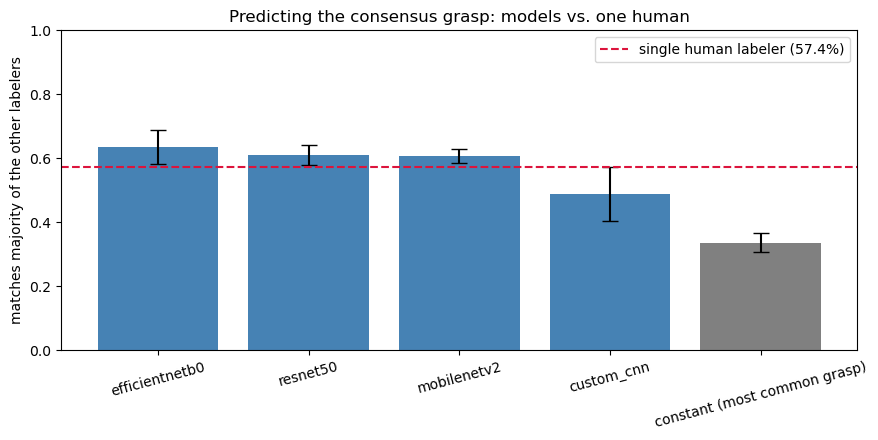

In [18]:
# Votes per instance from all labelers, then remove each image's own labeler -> the "other labelers"
votes = pd.crosstab(INSTANCE, HARD).reindex(columns=range(NUM_CLASSES), fill_value=0)
OTHERS = votes.loc[INSTANCE].values.copy()
OTHERS[np.arange(len(HARD)), HARD] -= 1

def agree_with_others(pred, idx):
    o = OTHERS[idx]
    return float((o[np.arange(len(idx)), pred] == o.max(axis=1)).mean())   # ties: any top choice counts

def f1_with_others(pred, idx):
    return macro_f1(OTHERS[idx].argmax(axis=1), pred)

rows = []
for name, rs in RESULTS.items():
    for r in rs:
        idx, pred = np.asarray(r["test_idx"]), r["probs"].argmax(axis=1)
        rows.append({"predictor": name, "fold": r["fold"], "agree": agree_with_others(pred, idx), "macro_f1": f1_with_others(pred, idx)})
for k, (tr, _, te) in enumerate(FOLDS):
    const = np.full(len(te), np.bincount(HARD[tr], minlength=NUM_CLASSES).argmax())
    rows.append({"predictor": "single human labeler", "fold": k, "agree": agree_with_others(HARD[te], te), "macro_f1": f1_with_others(HARD[te], te)})
    rows.append({"predictor": "constant (most common grasp)", "fold": k, "agree": agree_with_others(const, te), "macro_f1": f1_with_others(const, te)})

bench = pd.DataFrame(rows).groupby("predictor")[["agree", "macro_f1"]].agg(["mean", "std"])
bench = bench.sort_values(("agree", "mean"), ascending=False)
display(pd.DataFrame({c: bench[c]["mean"].map("{:.3f}".format) + " ± " + bench[c]["std"].map("{:.3f}".format) for c in ["agree", "macro_f1"]})
        .rename(columns={"agree": "matches majority of other labelers", "macro_f1": "macro-F1 (4 grasps)"}))

human = bench.loc["single human labeler", ("agree", "mean")]
fig, ax = plt.subplots(figsize=(9, 4.5))
order = [p for p in bench.index if p != "single human labeler"]
colors = ["gray" if p.startswith("constant") else "steelblue" for p in order]
ax.bar(order, bench.loc[order, ("agree", "mean")], yerr=bench.loc[order, ("agree", "std")], capsize=6, color=colors)
ax.axhline(human, color="crimson", ls="--", label=f"single human labeler ({human:.1%})")
ax.set_ylim(0, 1); ax.set_ylabel("matches majority of the other labelers")
ax.set_title("Predicting the consensus grasp: models vs. one human")
ax.tick_params(axis="x", rotation=15); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

## 9. Discussion

**Results in brief (5-fold group cross-validation, mean ± std).** EfficientNetB0 49.1 ± 4.5%, ResNet50 49.0 ± 4.0%, MobileNetV2 48.0 ± 3.7%, custom CNN 40.6 ± 6.8% accuracy against each image's own label, versus a 27.9% majority-class baseline and a 61.1% label-noise ceiling.
The three pretrained models are within one standard deviation of each other, so none is clearly best; MobileNetV2 matches the others at a fraction of the size. Against the **majority vote**, EfficientNetB0 reaches 60.5%, and **97%** of its predictions are a grasp at least one labeler chose.
Against the majority of the *other* labelers (Section 8.5), EfficientNetB0 agrees 63.5% of the time, and a single human labeler 57.4%: the models predict the consensus grasp at roughly human-level agreement, from the hand-camera image alone.

**Read the results relative to the ceiling, not to 100%.** Because the 11 labelers disagree, even a perfect model can't match every image's own label. The ceiling printed in Section 2.1 (~61%) is the real upper bound for `acc_own`. `acc_any` and `acc_instance` show how often the model picks a grasp that some human, or the majority of humans, would choose. Those are fairer measures for a prosthetic, since any reasonable grasp works.

**Why v1's ResNet50 and custom CNN scored ~33%.** That is about the majority-class baseline. Their confusion matrices would show a single dominant column.
For ResNet50, the main cause was preprocessing: `/255` inputs don't match the "caffe" preprocessing its ImageNet weights were trained with.

**Why the paper's 89% isn't comparable.**
1. The paper used sigmoid outputs with binary cross-entropy. Keras then scores "accuracy" over all 5 outputs separately (`binary_acc` here),
   so a model that outputs all zeros already gets 80%.
2. The dataset README says its `Train_Label.csv` / `Test_Label.csv` split was drawn randomly over *images*. Augmented copies of the same object
   can then appear in both train and test, which inflates the score.

This notebook uses a group-aware split and reports both metrics side by side.

**Limitations / next steps**
* v1's numbers come from a single split and v2's from 5-fold cross-validation, so the before/after comparison is indicative rather than exact.
* Open Palm has too few examples to learn. Consider dropping it (a 4-class problem) or collecting more.
* Next directions: train on a GPU (WSL2/Colab) to fit the larger backbones, use higher input resolution, fuse with the dataset's EMG/IMU signals as the paper proposes,
  and try ranking losses as in Han et al. (2019).